# Figure 3A: MC11 moved next to MC18

Nicola asked whether MC4 and MC11 should swap places in Figure 3A and confirmed she meant the figure. The text
describes MC11 together with MC18, so the rows now run MC0, MC2, MC5, MC3, MC18, MC11, MC4. Display only: the
saved composition matrix, cell-state order and colours, and clone support written by
`analysis_workspace/weinreb/20260916_complete_metaclone_overview/complete_overview_and_analysis.ipynb` are re-plotted
unchanged; only the row order differs from `reference_workspace/Figure/weinreb_figure3a_legend_right_20260918`.

Environment manager micromamba-compatible existing env **chronoclone**,
`/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone**.
Execution: `/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone figure_3a_mc11_order.ipynb`


In [1]:

import sys, platform, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl
import matplotlib.pyplot as plt
ROOT = Path('/path/to/ChronoClone')
OUT = ROOT / 'reference_workspace/Figure/weinreb_figure3a_mc11_order_20261113'
SRC = ROOT / 'analysis_workspace/weinreb/20260916_complete_metaclone_overview'
ENV = Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).resolve().parent.parent == ENV.resolve()
(OUT / 'panels').mkdir(parents=True, exist_ok=True)
def sha256(path):
    d = hashlib.sha256()
    with Path(path).open('rb') as s:
        for b in iter(lambda: s.read(8 * 1024 * 1024), b''): d.update(b)
    return d.hexdigest()
display({'name': 'chronoclone', 'path': str(ENV), 'manager': 'existing Conda-managed environment; not modified',
         'kernel': 'chronoclone', 'python': platform.python_version(), 'numpy': np.__version__,
         'pandas': pd.__version__, 'matplotlib': mpl.__version__, 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone /path/to/ChronoClone/reference_workspace/Figure/weinreb_figure3a_mc11_order_20261113/figure_3a_mc11_order.ipynb'})
MATRIX_SOURCE = SRC / 'tables/figure_3a_hspc_pooled_composition.csv'
ORDER_SOURCE = SRC / 'tables/figure_3a_cell_state_display_order.csv'
SUPPORT_SOURCE = SRC / 'tables/all_metaclone_day_support.csv'
PALETTE_SOURCE = ROOT / 'ChronoClone_paper/analysis/weinreb/inputs/manuscript_metaclone_palette.csv'
display(pd.DataFrame([{'source': str(p.relative_to(ROOT)), 'bytes': p.stat().st_size, 'sha256': sha256(p)}
                     for p in [MATRIX_SOURCE, ORDER_SOURCE, SUPPORT_SOURCE, PALETTE_SOURCE,
                               SRC / 'figures/figure_3a_hspc_pooled_composition.png']]))
# Styling of the panel being replaced (setup cell of the source notebook).
mpl.rcParams.update({'svg.fonttype': 'none', 'font.family': 'DejaVu Sans', 'font.size': 13,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False})
matrix = pd.read_csv(MATRIX_SOURCE)
order_table = pd.read_csv(ORDER_SOURCE).sort_values('display_order')
support = pd.read_csv(SUPPORT_SOURCE).set_index(['metaclone', 'day']).clones
PALETTE = pd.read_csv(PALETTE_SOURCE).set_index('label').color.to_dict()
stack_order = order_table.cell_state.tolist()
DISPLAY_COLORS = dict(zip(order_table.cell_state, order_table.color))
published = list(zip(matrix.metaclone.astype(int), matrix.day.astype(int)))   # row order of the published panel
MC_ORDER = [0, 2, 5, 3, 18, 11, 4]   # Nicola: MC11 next to MC18, MC4 last
assert sorted(MC_ORDER) == sorted(set(mc for mc, _ in published))
order = [(mc, day) for mc in MC_ORDER for day in (4, 6)]
assert sorted(order) == sorted(published)
matrix = matrix.set_index(['metaclone', 'day']).loc[order].reset_index()
assert np.allclose(matrix[stack_order].sum(axis=1), 1, atol=1e-10)
display(order_table); print('published rows:', published); print('new rows:', order)


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing Conda-managed environment; not modified',
 'kernel': 'chronoclone',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'matplotlib': '3.11.0',
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone /path/to/ChronoClone/reference_workspace/Figure/weinreb_figure3a_mc11_order_20261113/figure_3a_mc11_order.ipynb'}

,source,bytes,sha256
0,analysis_workspace/weinreb/20260916_complete_metacl...,3618,40dfc49c2ceb8e511e5857485fae7c90308cea847c53e4...
1,analysis_workspace/weinreb/20260916_complete_metacl...,957,c1b6a22ba6b3aa94ff8ed95c8edfcd1bb1c2ed3f823243...
2,analysis_workspace/weinreb/20260916_complete_metacl...,674,d2a900ed06be481805a8b036640ed7d9b3fca1bb1b3e56...
3,ChronoClone_paper/analysis/weinreb/inputs/manu...,630,8606561063d2d1c0326d9084881c91f247007992110672...
4,analysis_workspace/weinreb/20260916_complete_metacl...,261870,56cb597767de599b5e9c1a99b6ded985af529a404f8805...


,display_order,cell_state,stage,color
0,1,HSPCs,HSPCs and early progenitors,#787878
1,2,Prog 3,HSPCs and early progenitors,#a7a7a7
2,3,Prog 4,HSPCs and early progenitors,#c5c5c5
3,4,Baso/Mk/Ery/Mast prog,Multilineage-associated progenitors,#8cc493
4,5,Ly/pDC prog,Multilineage-associated progenitors,#85c5bf
5,6,DC/Mono prog,Multilineage-associated progenitors,#b55d76
6,7,Mk/Ery prog,Multilineage-associated progenitors,#89b6d5
7,8,Baso/Eos prog,Multilineage-associated progenitors,#78bd85
8,9,Early Neu prog,Lineage-associated progenitors,#f3c685
9,10,Neu prog,Lineage-associated progenitors,#f3a84d


published rows: [(0, 4), (0, 6), (2, 4), (2, 6), (5, 4), (5, 6), (3, 4), (3, 6), (18, 4), (18, 6), (4, 4), (4, 6), (11, 4), (11, 6)]
new rows: [(0, 4), (0, 6), (2, 4), (2, 6), (5, 4), (5, 6), (3, 4), (3, 6), (18, 4), (18, 6), (11, 4), (11, 6), (4, 4), (4, 6)]


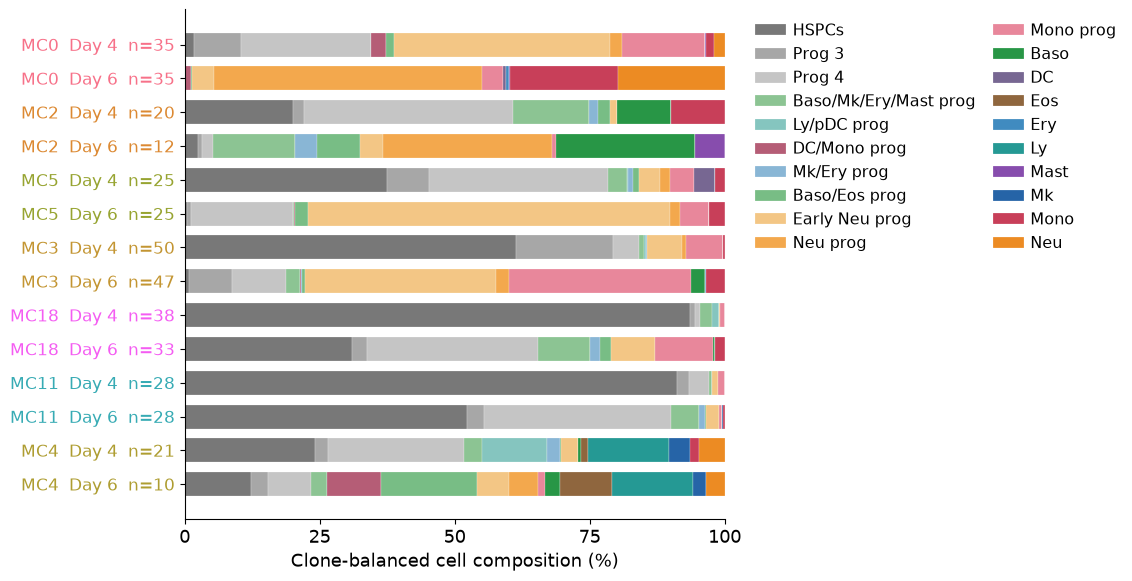

/path/to/ChronoClone/reference_workspace/Figure/weinreb_figure3a_mc11_order_20261113/panels/figure_3a_hspc_pooled_composition_mc11_order.svg d7dd7fc8e3f9dd0e7cbb9faf35b05d049dd3cd207554abbd0b962f65742dbad8


In [2]:

# Figure 3A, legend on the right in two columns; rows reordered so MC11 follows MC18 (`order`, set in the setup cell).
stem = 'figure_3a_hspc_pooled_composition_mc11_order'
fig = plt.figure(figsize=(12.6, 6.0))
ax = fig.add_axes([2.05 / 12.6, 0.75 / 6.0, 5.4 / 12.6, 5.1 / 6.0])
y = np.arange(len(order)); left = np.zeros(len(order))
for state in stack_order:
    values = matrix[state].to_numpy() * 100
    ax.barh(y, values, left=left, color=DISPLAY_COLORS[state], height=.71, edgecolor='white', linewidth=.15, label=state)
    left += values
labels = [f'MC{mc}  Day {day}  n={int(support.loc[(mc, day)])}' for mc, day in order]
ax.set_yticks(y, labels, fontsize=12); ax.invert_yaxis()
for tick, (mc, day) in zip(ax.get_yticklabels(), order): tick.set_color(PALETTE[f'MC{mc}'])
ax.set_xlim(0, 100); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel('Clone-balanced cell composition (%)')
# ncol=2 fills column by column, so the legend reads immature -> differentiated down column 1, then column 2.
ax.legend(ncol=2, loc='upper left', bbox_to_anchor=(1.03, 1.0), frameon=False, fontsize=11.3,
          handletextpad=.4, columnspacing=1.1)
svg = OUT / 'panels' / f'{stem}.svg'; png = svg.with_suffix('.png')
fig.savefig(svg, bbox_inches='tight', pad_inches=.13); fig.savefig(png, dpi=300, bbox_inches='tight', pad_inches=.13)
display(fig); plt.close(fig)
print(svg, sha256(svg))
